# 12. Black bodies and real surfaces

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 1

Every surface emits thermal radiation, and the amount grows as the fourth power of its
absolute temperature. Chapter 1 used this through the emissivity $\varepsilon$ of the
pipe cladding, and Chapter 9 found that radiation carries two thirds of the heat from an
electronics cabinet. This chapter looks inside $\varepsilon$. Radiation is spread over
wavelengths: the sun, at 5800 K, emits mostly visible and near-infrared light, while
everything around us, near 300 K, emits in the far infrared. A surface can absorb one band
well and emit in the other poorly, and solar collectors, low-emissivity windows and
thermal cameras all rest on this.

The engineering question is a solar water heater for a house in Kazakhstan. Its absorber
plate must take in as much sunlight as possible and lose as little heat as possible. A
black paint absorbs sunlight well, but it also emits strongly in the infrared; a
*selective* coating absorbs sunlight just as well and emits a twentieth as much. How much
better is the coating, and at what wavelength should it switch from absorbing to
reflecting? Planck's law gives the answers. The checks compute its integrals two ways, and
one of them found an error in a band-fraction formula that an earlier version of the
package used.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import warnings

from scipy.integrate import IntegrationWarning, quad
from scipy.optimize import brentq, minimize_scalar

try:
    from engtransport import radiation
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import radiation
from engtransport.plotting import panel_label, use_style

use_style()
SIGMA = radiation.SIGMA_SB

## 12.1 The black body

A *black body* absorbs all radiation falling on it, from every direction and at every
wavelength. A small hole into a large cavity behaves as one: radiation entering it is
reflected inside many times and is absorbed before it can find its way out. In equilibrium
the radiation inside, and so the radiation leaving the hole, depends only on the
temperature. Planck (1901) found its distribution over wavelength. The power emitted per
unit area of a black surface, per unit wavelength, is

$$
E_{b\lambda}(\lambda, T) = \frac{C_1}{\lambda^5\left[\exp(C_2/\lambda T) - 1\right]} ,
\qquad C_1 = 2\pi h c^2 , \quad C_2 = \frac{hc}{k_B} ,
\tag{12.1}
$$

with $h$ Planck's constant, $c$ the speed of light and $k_B$ Boltzmann's constant;
$C_1 = 3.742 \times 10^8$ W μm⁴/m² and $C_2 = 14\,388$ μm K. The distribution has a single
peak. Setting $\partial E_{b\lambda}/\partial\lambda = 0$ gives, with $x = C_2/\lambda T$,
the equation $x = 5(1 - e^{-x})$, whose root fixes *Wien's displacement law*

$$
\lambda_{max}T = b = 2897.77 \ \mu\mathrm{m\,K} .
\tag{12.2}
$$

The sun peaks near 0.5 μm, in the visible; a body at room temperature near 10 μm.
Integrating Eq. (12.1) over all wavelengths gives the *Stefan–Boltzmann law*,

$$
E_b = \int_0^\infty E_{b\lambda}\,d\lambda = \sigma T^4 , \qquad
\sigma = \frac{2\pi^5 k_B^4}{15 h^3 c^2} = 5.670 \times 10^{-8}\ \mathrm{W/(m^2\,K^4)} ,
\tag{12.3}
$$

since $\int_0^\infty z^3/(e^z - 1)\,dz = \pi^4/15$. The fraction of the emission below a
wavelength $\lambda$ depends only on the product $\lambda T$:

$$
F(\lambda T) = \frac{1}{\sigma T^4}\int_0^\lambda E_{b\lambda}\,d\lambda
= \frac{15}{\pi^4}\int_{C_2/\lambda T}^\infty \frac{z^3\,dz}{e^z - 1}
= \frac{15}{\pi^4}\sum_{m=1}^\infty \frac{e^{-mx}}{m^4}\left(m^3x^3 + 3m^2x^2 + 6mx + 6\right) ,
\tag{12.4}
$$

with $x = C_2/\lambda T$; the series converges fast for $x$ larger than about 0.5, and a
power series in $x$ covers the rest (`radiation.blackbody_band_fraction`).

In [2]:
print(f"sigma from h, c, k: {radiation.stefan_boltzmann_from_constants():.10e} W/(m2 K4)")
print(f"Wien's constant from x = 5(1 - exp(-x)): {radiation.wien_constant():.4f} um K")
for name, T in (("room, 300 K", 300.0), ("furnace wall, 1300 K", 1300.0), ("tungsten filament, 2800 K", 2800.0),
                ("sun, 5772 K", radiation.T_SUN)):
    vis = radiation.band_fraction(0.38, 0.78, T)
    below3 = radiation.blackbody_band_fraction(3.0 * T)
    print(f"{name:26s}: peak at {radiation.WIEN_B / T:6.2f} um; visible (0.38-0.78 um) {100 * vis:5.1f} %;"
          f" below 3 um {100 * below3:5.1f} %")
G_space = SIGMA * radiation.T_SUN**4 * (radiation.R_SUN / radiation.AU) ** 2
print(f"sun as a black body at 5772 K, seen from 1 AU: {G_space:.1f} W/m2 (measured total solar irradiance 1360.8 W/m2)")

sigma from h, c, k: 5.6703744192e-08 W/(m2 K4)
Wien's constant from x = 5(1 - exp(-x)): 2897.7720 um K
room, 300 K               : peak at   9.66 um; visible (0.38-0.78 um)   0.0 %; below 3 um   0.0 %
furnace wall, 1300 K      : peak at   2.23 um; visible (0.38-0.78 um)   0.0 %; below 3 um  46.2 %
tungsten filament, 2800 K : peak at   1.03 um; visible (0.38-0.78 um)   9.7 %; below 3 um  87.1 %
sun, 5772 K               : peak at   0.50 um; visible (0.38-0.78 um)  46.5 %; below 3 um  97.9 %
sun as a black body at 5772 K, seen from 1 AU: 1361.2 W/m2 (measured total solar irradiance 1360.8 W/m2)


Of the sun's emission, 47 % is visible and 98 % lies below 3 μm; of a body at room
temperature, almost nothing lies below 3 μm. The two bands hardly overlap, and that is
what a selective surface exploits. A tungsten lamp at 2800 K puts only 10 % of its
emission into the visible, which is why incandescent lamps were so inefficient.

The sun is close to a black body at its nominal effective temperature of 5772 K: diluted by
the square of its radius over its distance, its emission gives 1361 W/m² above the
atmosphere, against the 1360.8 W/m² measured by Kopp and Lean (2011). (The nominal
temperature is itself defined from the measured luminosity, so this agreement is a
consistency check rather than a test.) At the ground on a clear day the atmosphere leaves
roughly 800–1000 W/m², with absorption bands of water vapour and carbon dioxide cut out of
the infrared part.

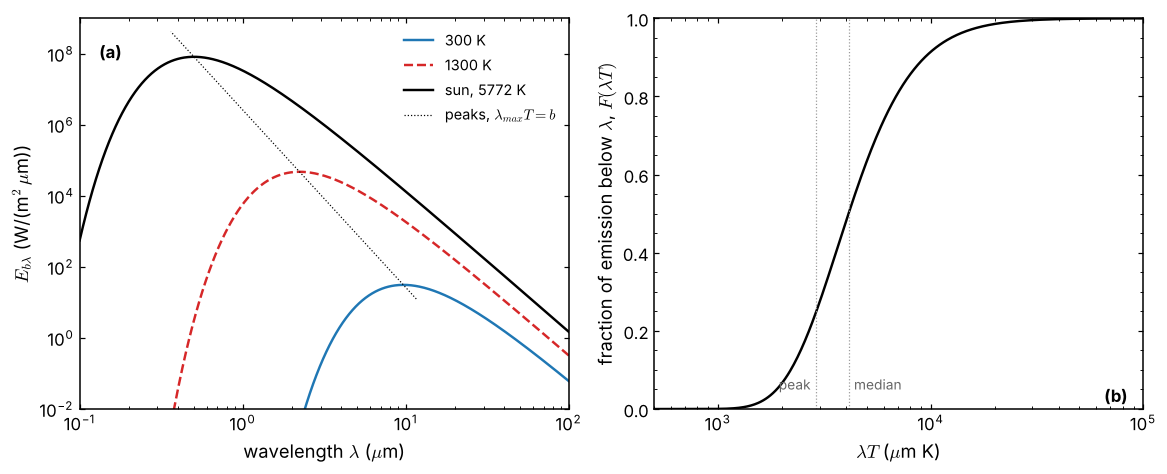

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
lam = np.geomspace(0.1, 100.0, 600)
for T, style in ((300.0, "C0-"), (1300.0, "C3--"), (radiation.T_SUN, "k-")):
    label = "sun, 5772 K" if T == radiation.T_SUN else f"{T:.0f} K"
    ax1.loglog(lam, radiation.planck_spectral_emissive_power(lam, T), style, label=label)
Ts = np.geomspace(250, 8000, 50)
ax1.loglog(radiation.WIEN_B / Ts, radiation.planck_spectral_emissive_power(radiation.WIEN_B / Ts, Ts), "k:", lw=0.8,
           label=r"peaks, $\lambda_{max}T = b$")
ax1.set_xlabel(r"wavelength $\lambda$ ($\mu$m)")
ax1.set_ylabel(r"$E_{b\lambda}$ (W/(m$^2\,\mu$m))")
ax1.set_xlim(0.1, 100)
ax1.set_ylim(1e-2, 1e9)
ax1.legend(loc="upper right")
panel_label(ax1, "(a)", x=0.04, y=0.94)

lamT = np.geomspace(500, 1e5, 400)
ax2.semilogx(lamT, radiation.blackbody_band_fraction(lamT), "k-")
for val, txt, ha, fac in ((radiation.WIEN_B, "peak", "right", 0.94), (4110.0, "median", "left", 1.06)):
    ax2.axvline(val, color="0.6", ls=":", lw=0.8)
    ax2.text(val * fac, 0.05, txt, color="0.4", fontsize=9, ha=ha)
ax2.set_xlabel(r"$\lambda T$ ($\mu$m K)")
ax2.set_ylabel(r"fraction of emission below $\lambda$, $F(\lambda T)$")
ax2.set_xlim(500, 1e5)
ax2.set_ylim(0, 1)
panel_label(ax2, "(b)", x=0.92, y=0.06)
plt.show()

**Figure 12.1.** (a) Planck's distribution, Eq. (12.1), for a room at 300 K, a furnace wall at
1300 K and the sun at 5772 K, with the locus of the peaks, Eq. (12.2). (b) The fraction of
blackbody emission below a wavelength, Eq. (12.4); a quarter of the emission lies below
the peak and half below $\lambda T \approx 4110$ μm K.

## 12.2 Real surfaces and Kirchhoff's law

A real surface emits less than a black body at the same temperature. Its *spectral
emissivity* $\varepsilon_\lambda$ is the ratio at each wavelength, and its *total
emissivity* is the average weighted by Planck's distribution at its own temperature:

$$
\varepsilon(T) = \frac{1}{\sigma T^4}\int_0^\infty \varepsilon_\lambda(\lambda)\,E_{b\lambda}(\lambda, T)\,d\lambda .
\tag{12.5}
$$

Radiation falling on a surface is absorbed, reflected or, for glass and films,
transmitted. Kirchhoff (1860) showed from the equilibrium of a body inside a black cavity
that a surface absorbs at each wavelength and direction exactly the fraction it would emit,
$\alpha_\lambda = \varepsilon_\lambda$. The *total absorptivity*, though, is weighted by the
spectrum of the incoming radiation, $G_\lambda$, not by the surface's own emission:

$$
\alpha = \frac{\int_0^\infty \alpha_\lambda\,G_\lambda\,d\lambda}{\int_0^\infty G_\lambda\,d\lambda} ,
\qquad \alpha_\lambda = \varepsilon_\lambda .
\tag{12.6}
$$

So $\alpha = \varepsilon$ only when the incoming radiation has the spectrum of a black body
at the surface's own temperature, or when $\varepsilon_\lambda$ does not depend on
wavelength (a *grey* surface). For sunlight on a surface near room temperature, $\alpha$
and $\varepsilon$ are averages over different bands and can differ greatly: white paint
absorbs perhaps a quarter of the sunlight but emits as well as black paint in the infrared.

## 12.3 A selective absorber

The simplest model of a selective coating is a step: $\varepsilon_\lambda = a$ below a cutoff
wavelength $\lambda_c$ and $b$ above it. With Eq. (12.4) its solar absorptance (sunlight as a
black body at 5772 K) and its emissivity at its own temperature $T$ are

$$
\alpha_s = a\,F(\lambda_cT_{sun}) + b\,[1 - F(\lambda_cT_{sun})] , \qquad
\varepsilon(T) = a\,F(\lambda_cT) + b\,[1 - F(\lambda_cT)] .
\tag{12.7}
$$

An unglazed absorber plate, insulated behind, in sunlight $G$ and air at $T_a$, delivers to
the water flowing under it the useful heat flux

$$
q_u = \alpha_s G - h(T - T_a) - \varepsilon(T)\,\sigma\left(T^4 - T_{sky}^4\right) ,
\tag{12.8}
$$

where $h$ is the convective coefficient of the wind and $T_{sky}$ the effective temperature
of the sky, taken here as 15 K below the air. With no water flowing, $q_u = 0$ and the
plate reaches its *stagnation temperature*. The heater is in Astana on a summer day:
$G = 800$ W/m², air at 20 °C, a light wind with $h = 8$ W/(m² K). It compares black paint
($\alpha = 0.95$, $\varepsilon = 0.90$, grey) with a step coating ($a = 0.95$, $b = 0.05$,
$\lambda_c = 2.5$ μm), values typical of commercial coatings:

In [4]:
G, T_a, h_wind = 800.0, 273.15 + 20.0, 8.0
T_sky = T_a - 15.0
coat = radiation.step_surface(2.5, 0.95, 0.05)
alpha_sel = coat["absorptance"]()
print(f"step coating, lambda_c = 2.5 um: solar absorptance {alpha_sel:.4f}; emissivity at 60 C {coat['emissivity'](333.15):.4f},"
      f" at 200 C {coat['emissivity'](473.15):.4f}")


def useful(T, surface, G=G, h=h_wind):
    if surface == "paint":
        a, e = 0.95, 0.90
    else:
        a, e = alpha_sel, coat["emissivity"](T)
    return a * G - h * (T - T_a) - e * SIGMA * (T**4 - T_sky**4)


for surface in ("paint", "selective"):
    T_st = brentq(lambda T: useful(T, surface), T_a, 900.0)
    print(f"{surface:9s}: stagnation {T_st - 273.15:5.1f} C; efficiency q_u/G at 40 C {useful(313.15, surface) / G:5.3f},"
          f" at 60 C {useful(333.15, surface) / G:5.3f}, at 80 C {useful(353.15, surface) / G:6.3f}")
T60 = 333.15
loss_rad = {"paint": 0.90 * SIGMA * (T60**4 - T_sky**4), "selective": coat["emissivity"](T60) * SIGMA * (T60**4 - T_sky**4)}
print(f"at 60 C: convective loss {h_wind * (T60 - T_a):.0f} W/m2; radiative loss {loss_rad['paint']:.0f} W/m2 (paint),"
      f" {loss_rad['selective']:.0f} W/m2 (coating)")

step coating, lambda_c = 2.5 um: solar absorptance 0.9191; emissivity at 60 C 0.0500, at 200 C 0.0517
paint    : stagnation  67.4 C; efficiency q_u/G at 40 C 0.518, at 60 C 0.146, at 80 C -0.260
selective: stagnation 106.6 C; efficiency q_u/G at 40 C 0.706, at 60 C 0.497, at 80 C  0.285
at 60 C: convective loss 320 W/m2; radiative loss 323 W/m2 (paint), 18 W/m2 (coating)


At 60 °C, a typical temperature for domestic hot water, the painted plate delivers only
15 % of the sunlight: it radiates 320 W/m² to the sky, more than 40 % of what it absorbs.
The selective coating radiates 18 W/m² and delivers 50 %. Its stagnation temperature is 107 °C
against 67 °C for paint. Behind glass, which cuts the convective loss and returns part of
the infrared, the difference is larger still; the coating is what makes a collector useful
above 60 °C.

Where should the coating switch from absorbing to reflecting? Moving the cutoff to longer
wavelengths absorbs more sunlight but also emits more. Differentiating the net absorbed
flux, $\alpha_sG - \varepsilon(T)\sigma T^4$, with respect to $\lambda_c$ gives
$(a - b)\left[G_\lambda(\lambda_c) - E_{b\lambda}(\lambda_c, T)\right] = 0$: the best cutoff is
where the solar spectrum and the plate's own blackbody spectrum cross,

$$
G_\lambda(\lambda_c) = E_{b\lambda}(\lambda_c, T) .
\tag{12.9}
$$

In [5]:
def net_flux(lam_c, T, G=G):
    s = radiation.step_surface(lam_c, 0.95, 0.05)
    return s["absorptance"]() * G - s["emissivity"](T) * SIGMA * T**4


def crossing(T, G=G):
    return brentq(lambda lc: radiation.solar_spectrum(lc, G) - radiation.planck_spectral_emissive_power(lc, T), 0.8, 30.0)


for T_C in (60.0, 100.0, 200.0, 400.0):
    T = T_C + 273.15
    lc = crossing(T)
    print(f"plate at {T_C:3.0f} C: best cutoff {lc:.2f} um; net {net_flux(lc, T):.0f} W/m2"
          f" (with a 2.5 um cutoff {net_flux(2.5, T):.0f} W/m2)")

plate at  60 C: best cutoff 3.86 um; net 715 W/m2 (with a 2.5 um cutoff 700 W/m2)
plate at 100 C: best cutoff 3.40 um; net 691 W/m2 (with a 2.5 um cutoff 680 W/m2)
plate at 200 C: best cutoff 2.59 um; net 589 W/m2 (with a 2.5 um cutoff 588 W/m2)
plate at 400 C: best cutoff 1.72 um; net 99 W/m2 (with a 2.5 um cutoff -129 W/m2)


For a plate at 60–100 °C the best cutoff lies at 3.4–3.9 μm, but the gain over a 2.5 μm
cutoff is small; for a plate at 400 °C, as in concentrating collectors, the optimum moves
in to 1.7 μm, because the plate's own emission shifts to shorter wavelengths.

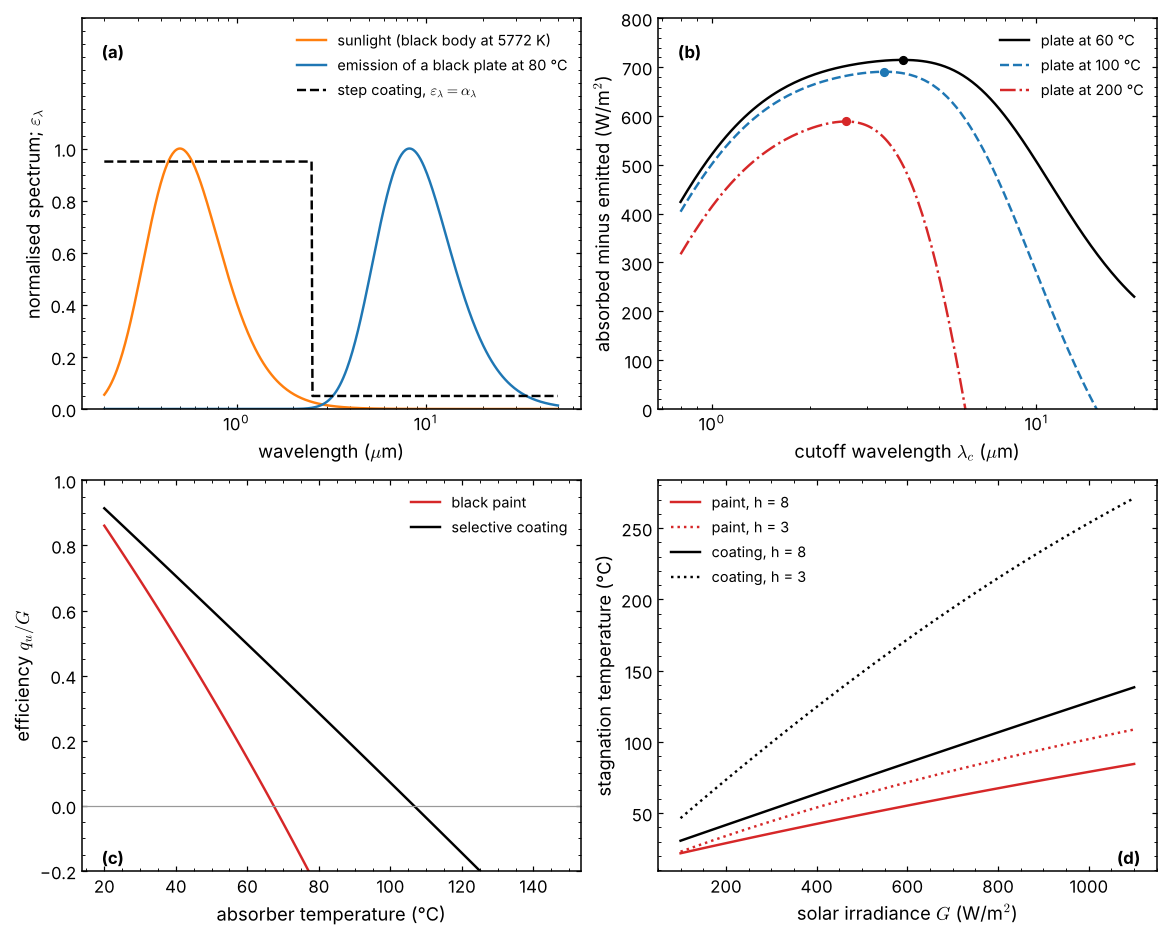

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

lam = np.geomspace(0.2, 50.0, 500)
sun = radiation.solar_spectrum(lam, G)
plate = radiation.planck_spectral_emissive_power(lam, 353.15)
ax1.semilogx(lam, sun / sun.max(), "C1-", label="sunlight (black body at 5772 K)")
ax1.semilogx(lam, plate / plate.max(), "C0-", label="emission of a black plate at 80 °C")
ax1.semilogx(lam, np.where(lam < 2.5, 0.95, 0.05), "k--", label=r"step coating, $\varepsilon_\lambda = \alpha_\lambda$")
ax1.set_xlabel(r"wavelength ($\mu$m)")
ax1.set_ylabel(r"normalised spectrum; $\varepsilon_\lambda$")
ax1.set_ylim(0, 1.5)
ax1.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax1.legend(loc="upper right")
panel_label(ax1, "(a)", x=0.04, y=0.94)

lcs = np.geomspace(0.8, 20.0, 200)
for T_C, color, ls in ((60.0, "k", "-"), (100.0, "C0", "--"), (200.0, "C3", "-.")):
    T = T_C + 273.15
    ax2.semilogx(lcs, [net_flux(lc, T) for lc in lcs], color=color, ls=ls, label=f"plate at {T_C:.0f} °C")
    lc = crossing(T)
    ax2.plot(lc, net_flux(lc, T), "o", color=color, ms=5)
ax2.set_xlabel(r"cutoff wavelength $\lambda_c$ ($\mu$m)")
ax2.set_ylabel(r"absorbed minus emitted (W/m$^2$)")
ax2.set_ylim(0, 800)
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", x=0.04, y=0.94)

T_plate = np.linspace(T_a, 420.0, 100)
for surface, style in (("paint", "C3-"), ("selective", "k-")):
    eta = np.array([useful(T, surface) / G for T in T_plate])
    ax3.plot(T_plate - 273.15, eta, style, label="black paint" if surface == "paint" else "selective coating")
ax3.axhline(0.0, color="0.6", lw=0.8)
ax3.set_xlabel("absorber temperature (°C)")
ax3.set_ylabel(r"efficiency $q_u/G$")
ax3.set_ylim(-0.2, 1.0)
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.06)

Gs = np.linspace(100.0, 1100.0, 41)
for surface, color in (("paint", "C3"), ("selective", "k")):
    for h_val, ls in ((8.0, "-"), (3.0, ":")):
        T_st = [brentq(lambda T: useful(T, surface, G=g, h=h_val), T_a, 1200.0) - 273.15 for g in Gs]
        ax4.plot(Gs, T_st, color=color, ls=ls, label=f"{'paint' if surface == 'paint' else 'coating'}, h = {h_val:.0f}")
ax4.set_xlabel(r"solar irradiance $G$ (W/m$^2$)")
ax4.set_ylabel("stagnation temperature (°C)")
ax4.legend(loc="upper left")
panel_label(ax4, "(d)", x=0.92, y=0.06)
plt.show()

**Figure 12.2.** (a) The solar spectrum and the emission of a plate at 80 °C, each scaled to
its peak, with the spectral emissivity of the step coating. (b) Net flux absorbed by a
coated plate against the cutoff wavelength, for plates at 60, 100 and 200 °C; the dots are
the crossing condition (12.9). (c) Efficiency of an unglazed absorber in Astana sunlight
(800 W/m², air at 20 °C, wind $h = 8$ W/(m² K)) against its temperature. (d) Stagnation
temperature against the irradiance, in a light wind and in nearly still air.

## 12.4 Checks

**The band fraction.** The series (12.4) is compared with a direct numerical quadrature
of $z^3/(e^z - 1)$ (`scipy.integrate.quad`) over $300 \le \lambda T \le 10^7$ μm K. The same
comparison is made for a two-series formula used in an earlier version of the package, which
switched from a six-term power series to the exponential series at $x = 2$.

**The Stefan–Boltzmann law.** Planck's law is integrated numerically over wavelength on a
logarithmic grid, and the result is compared with $\sigma T^4$ from Eq. (12.3).

**The optimum cutoff.** The cutoff that maximises the net flux, found by numerical
optimisation, is compared with the crossing condition (12.9).

In [7]:
def F_quad(lamT):
    x = radiation.C2_PLANCK / lamT
    return 15 / math.pi**4 * quad(lambda z: z**3 * math.exp(-z) / -math.expm1(-z), x, np.inf, epsabs=1e-16, epsrel=1e-14)[0]


def F_two_series(lamT, n_terms=25):
    """The two-series band fraction of an earlier version of the package, reproduced for the check."""
    x = radiation.C2_PLANCK / lamT
    if x < 2.0:
        tail = x**3 * (1 / 3 - x / 8 + x**2 / 60 - x**4 / 5040 + x**6 / 272160 - x**8 / 13305600)
        return 1.0 - 15 / math.pi**4 * tail
    return 15 / math.pi**4 * sum(math.exp(-m * x) / m**4 * ((m * x) ** 3 + 3 * (m * x) ** 2 + 6 * m * x + 6) for m in range(1, n_terms + 1))


lamTs = np.geomspace(300.0, 1e7, 300)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", IntegrationWarning)          # quad warns of roundoff near 1e-16
    Fq = np.array([F_quad(v) for v in lamTs])
err_new = np.abs(radiation.blackbody_band_fraction(lamTs) - Fq)
err_old = np.abs(np.array([F_two_series(v) for v in lamTs]) - Fq)
print(f"band fraction, series against quadrature: largest error {err_new.max():.1e}")
print(f"the two-series formula: largest error {err_old.max():.1e} at lambda T = {lamTs[np.argmax(err_old)]:.0f} um K")

n_pts = [25, 50, 100, 200, 400]
err_sb = []
for n in n_pts:
    lam_g = np.geomspace(0.05, 1e6, n)
    E = radiation.planck_spectral_emissive_power(lam_g, 1000.0)
    err_sb.append(abs(np.trapezoid(E * lam_g, np.log(lam_g)) / (SIGMA * 1000.0**4) - 1))
err_sb = np.array(err_sb)
print("Stefan-Boltzmann, trapezoidal rule in ln(lambda): relative errors", " ".join(f"{e:.1e}" for e in err_sb))
print(f"sigma from the constants differs from the CODATA value by {radiation.stefan_boltzmann_from_constants() / SIGMA - 1:.1e}")

T_opt = np.linspace(300.0, 900.0, 13)
lc_opt = np.array([minimize_scalar(lambda lc: -net_flux(lc, T), bounds=(0.5, 20.0), method="bounded",
                                   options={"xatol": 1e-10}).x for T in T_opt])
lc_cross = np.array([crossing(T) for T in T_opt])
print(f"optimum cutoff by optimisation against the crossing condition: largest difference {np.max(np.abs(lc_opt - lc_cross)):.1e} um")
peak_num = np.array([minimize_scalar(lambda l: -radiation.planck_spectral_emissive_power(l, T), bounds=(0.1, 50.0), method="bounded",
                                     options={"xatol": 1e-12}).x * T for T in (300.0, 1300.0, 5772.0)])
print("peak lambda*T found numerically:", " ".join(f"{v:.4f}" for v in peak_num), f"(Eq. 12.2: {radiation.wien_constant():.4f})")

band fraction, series against quadrature: largest error 1.1e-15
the two-series formula: largest error 1.3e-06 at lambda T = 7392 um K
Stefan-Boltzmann, trapezoidal rule in ln(lambda): relative errors 1.1e-03 5.1e-09 3.3e-11 3.3e-11 3.3e-11
sigma from the constants differs from the CODATA value by 3.3e-11
optimum cutoff by optimisation against the crossing condition: largest difference 1.1e-07 um
peak lambda*T found numerically: 2897.7719 2897.7720 2897.7720 (Eq. 12.2: 2897.7720)


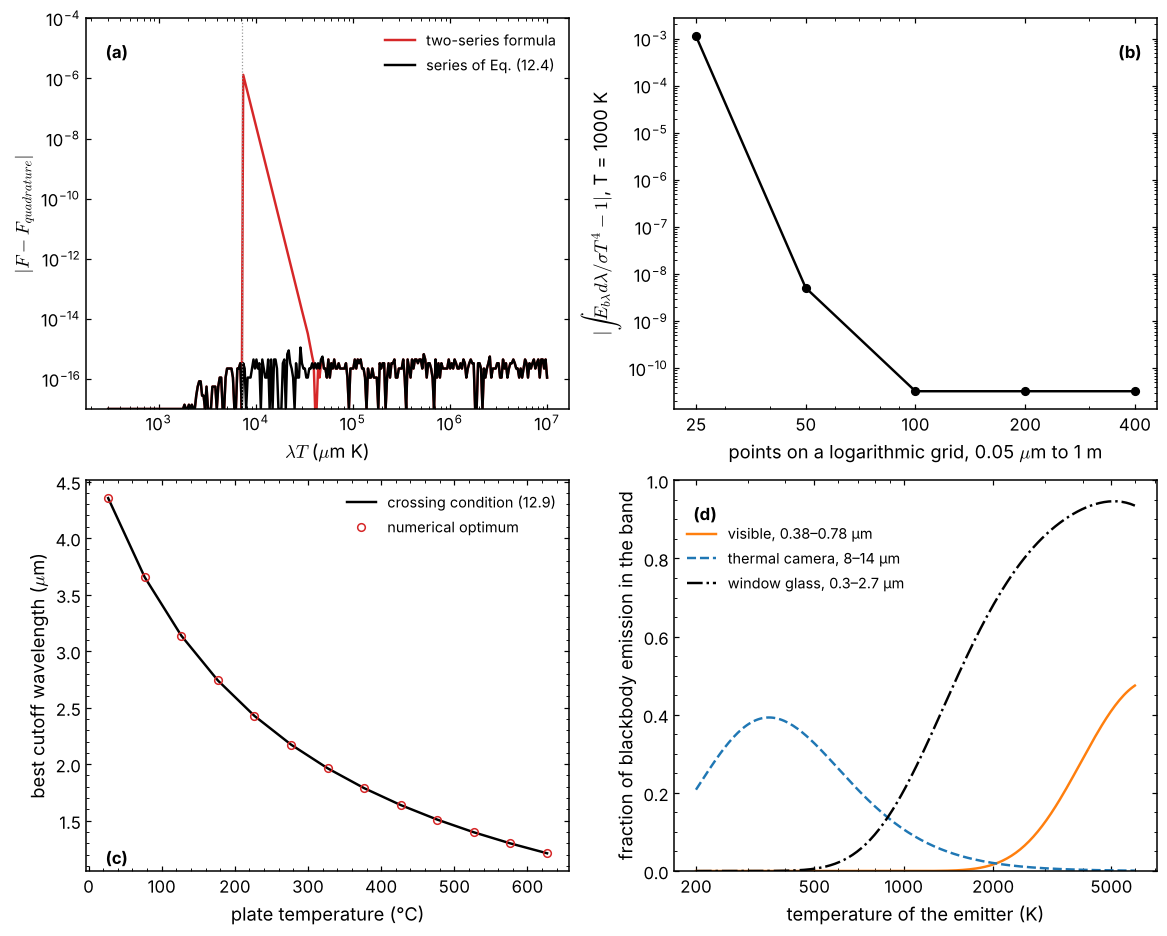

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

ax1.loglog(lamTs, np.maximum(err_old, 1e-17), "C3-", label="two-series formula")
ax1.loglog(lamTs, np.maximum(err_new, 1e-17), "k-", label="series of Eq. (12.4)")
ax1.axvline(radiation.C2_PLANCK / 2.0, color="0.6", ls=":", lw=0.8)
ax1.set_xlabel(r"$\lambda T$ ($\mu$m K)")
ax1.set_ylabel(r"$|F - F_{quadrature}|$")
ax1.set_ylim(1e-17, 1e-4)
ax1.legend(loc="upper right")
panel_label(ax1, "(a)", x=0.04, y=0.94)

ax2.loglog(n_pts, err_sb, "ko-", ms=5)
ax2.set_xticks(n_pts)
ax2.xaxis.set_major_formatter(plt.ScalarFormatter())
ax2.xaxis.set_minor_formatter(plt.NullFormatter())
ax2.set_xlabel(r"points on a logarithmic grid, 0.05 $\mu$m to 1 m")
ax2.set_ylabel(r"$|\int E_{b\lambda}d\lambda / \sigma T^4 - 1|$, T = 1000 K")
panel_label(ax2, "(b)", x=0.92, y=0.94)

ax3.plot(T_opt - 273.15, lc_cross, "k-", label="crossing condition (12.9)")
ax3.plot(T_opt - 273.15, lc_opt, "C3o", ms=5, mfc="none", label="numerical optimum")
ax3.set_xlabel("plate temperature (°C)")
ax3.set_ylabel(r"best cutoff wavelength ($\mu$m)")
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.06)

T_band = np.geomspace(200.0, 6000.0, 200)
for (l1, l2), style, label in (((0.38, 0.78), "C1-", "visible, 0.38–0.78 μm"), ((8.0, 14.0), "C0--", "thermal camera, 8–14 μm"),
                               ((0.3, 2.7), "k-.", "window glass, 0.3–2.7 μm")):
    ax4.semilogx(T_band, [radiation.band_fraction(l1, l2, T) for T in T_band], style, label=label)
ax4.set_xticks([200, 500, 1000, 2000, 5000])
ax4.xaxis.set_major_formatter(plt.ScalarFormatter())
ax4.xaxis.set_minor_formatter(plt.NullFormatter())
ax4.set_xlabel("temperature of the emitter (K)")
ax4.set_ylabel("fraction of blackbody emission in the band")
ax4.set_ylim(0, 1)
ax4.legend(loc="upper left", bbox_to_anchor=(0.0, 0.92))
panel_label(ax4, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 12.3.** Checks and band fractions. (a) Error of the band fraction against direct
quadrature, for Eq. (12.4) and for the two-series formula; the dotted line is where
that formula switches series. (b) Error of the Stefan–Boltzmann integral on a logarithmic
wavelength grid. (c) The best cutoff of a step coating, by numerical optimisation and by
the crossing condition. (d) Fractions of blackbody emission in three bands, against the
temperature of the emitter, from Eq. (12.4).

The series (12.4) agrees with quadrature to $10^{-15}$ everywhere. The two-series
formula, which claimed $10^{-12}$, was wrong by more than $10^{-6}$ just above
$\lambda T = 7194$ μm K, where it switched from a power series truncated too early to the
exponential series. The error is too small to matter in any engineering calculation, but it
is a reminder that a stated accuracy is a claim to be checked, not trusted. On a logarithmic
grid, the trapezoidal rule integrates Planck's law to $\sigma T^4$ with an error that falls
faster than any power of the number of points, down to $3 \times 10^{-11}$, the rounding of
the tabulated $\sigma$, with 100 points; and the
optimum cutoff and the crossing condition agree to $10^{-7}$ μm.

## 12.5 What to trust

* *The sun is not a black body at the ground.* Atmospheric absorption removes several bands
  in the infrared and scatters blue light; for solar absorptance the difference from a
  5772 K black body is a few per cent.
* *Real coatings* change from absorbing to reflecting over a band of wavelengths, not at a
  step (Exercise 4), and age in sunlight and moisture.
* *Emissivity depends on direction.* Metals emit more at grazing angles and dielectrics
  less; the hemispherical values used here are averages.
* *The sky temperature* depends strongly on humidity and cloud; 15 K below the air is a
  rough value for a clear summer day.

## Summary

* Planck's law (12.1) gives the spectrum of a black body; its peak follows Wien's law (12.2)
  and its integral the Stefan–Boltzmann law (12.3).
* The fraction of emission in a band depends only on $\lambda T$, Eq. (12.4).
* A real surface emits a fraction $\varepsilon$ of the blackbody emission, Eq. (12.5), and by
  Kirchhoff's law absorbs at each wavelength as it emits; total absorptivity and emissivity
  differ when the incoming radiation comes from a source at another temperature, Eq. (12.6).
* A selective coating (12.7) absorbs sunlight like black paint and emits a twentieth as
  much; it raises the efficiency of an absorber at 60 °C from 15 to 50 %, Eq. (12.8). Its
  best cutoff is where the solar and plate spectra cross, Eq. (12.9).

## Exercises

Sample solutions are in [`solutions/part3_radiation/12_solutions.ipynb`](../../solutions/part3_radiation/12_solutions.ipynb).

1. **The incandescent lamp.** A tungsten filament at 2800 K emits as a grey body. What
   fraction of its emission is visible (0.38–0.78 μm)? At what temperature would the visible
   fraction be largest, and why can lamps not run there?
2. **Why a car warms in the sun.** Window glass transmits between about 0.3 and 2.7 μm and is
   nearly opaque outside. What fraction of sunlight passes through it, and what fraction of
   the emission of a car interior at 60 °C could escape through it?
3. **A thermal camera.** Building inspectors use cameras sensitive between 8 and 14 μm. What
   fraction of the emission of a wall at 0 °C and at 20 °C falls in this band, and how much
   does the in-band signal change per kelvin near 0 °C? Why are such cameras not used for
   furnaces at 1300 K?
4. **A real coating.** The spectral emissivity of a coating falls linearly in $\log\lambda$
   from 0.95 at 1.5 μm to 0.05 at 4 μm. Find its solar absorptance and its emissivity at
   100 °C by integrating Eqs. (12.5) and (12.6), and compare with the step model with
   $\lambda_c = 2.5$ μm.

## Suggested references

* M. Planck, "Ueber das Gesetz der Energieverteilung im Normalspectrum", *Ann. Phys.*
  **309**, 553 (1901).
* G. Kirchhoff, "Ueber das Verhältniss zwischen dem Emissionsvermögen und dem
  Absorptionsvermögen der Körper für Wärme und Licht", *Ann. Phys.* **185**, 275 (1860).
* G. Kopp and J. L. Lean, "A new, lower value of total solar irradiance: evidence and
  climate significance", *Geophys. Res. Lett.* **38**, L01706 (2011).
* E. E. Mamajek et al., "IAU 2015 Resolution B3 on recommended nominal conversion constants
  for selected solar and planetary properties", arXiv:1510.07674 (2015).
* M. F. Modest and S. Mazumder, *Radiative Heat Transfer*, 4th ed. (Academic Press, 2022).

---

**Previous:** [11. Heat exchangers](../part2_convection/11_heat_exchangers.ipynb) &nbsp;·&nbsp; **Next:** [13. View factors and enclosures](13_view_factors_enclosures.ipynb)